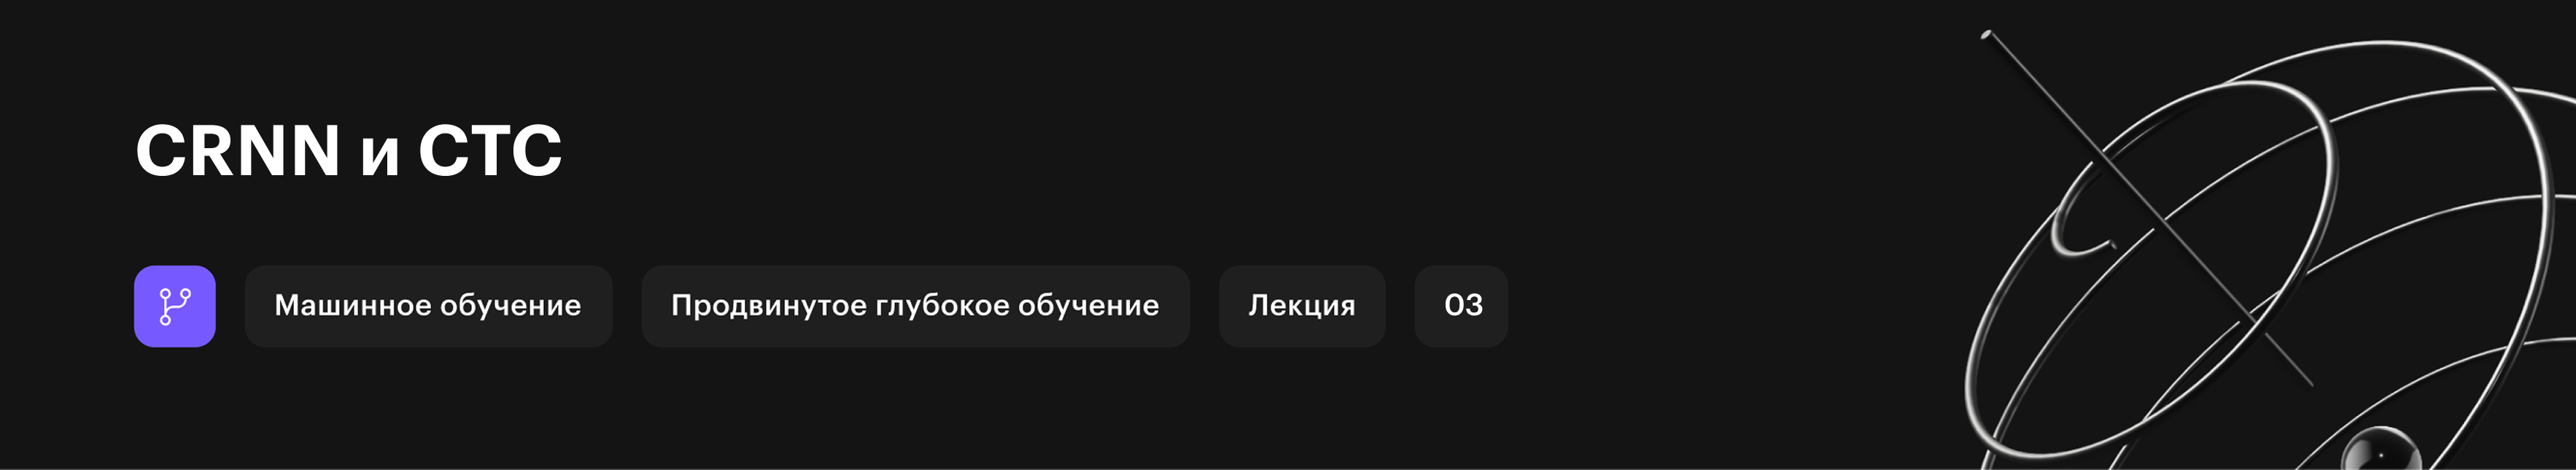

# 3. Моделирование последовательных данных

## План
1. Данные фиксированной длины vs последовательные (временные) данные.
2. Типы задач с последовательными данными.
3. Авторегрессионные модели. Модели Маркова.
4. Рекуррентные нейронные сети: `RNN`, `LSTM`, `GRU`.

In [ ]:
import plotly.graph_objects as go
import torch.nn             as nn
import torch
import math

from dataclasses import dataclass
from typing      import Optional

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

def set_seed(seed: int = 0):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def batch_to_device(batch, device):
    return [b.to(device) if torch.is_tensor(b) else b for b in batch]

Device: cuda


## Данные фиксированной длины vs последовательные (временные) данные

### Данные фиксированной длины

Данные фиксированной длины представляют собой набор независимых наблюдений, каждое из которых описывается вектором признаков фиксированной размерности. К таким данным относятся, например, табличные записи с числовыми и категориальными признаками, а также изображения, которые после оцифровки могут быть представлены как векторы пикселей или тензоры заданного размера. Ключевая особенность этих данных заключается в том, что порядок наблюдений не имеет значения, а сами наблюдения обычно предполагаются независимыми и одинаково распределёнными (i. i. d.). В этом случае задача обучения сводится к аппроксимации статической зависимости вида $y=f(x)$, где каждому объекту сопоставляется выходное значение и качество модели не зависит от того, в каком порядке объекты подаются на вход.

### Последовательные (временные) данные

Последовательные данные представляют собой упорядоченные во времени наблюдения, между которыми существует явная зависимость, поэтому каждое значение определяется не только текущими признаками, но и предшествующим контекстом. Типичными примерами таких данных являются временные ряды, текст, аудиосигналы и видеопоследовательности, где отдельные элементы не могут рассматриваться изолированно. В отличие от данных фиксированной длины, здесь порядок элементов критически важен, а предположение независимости наблюдений нарушается. Каждое наблюдение $x_t$ зависит от предыдущих состояний
$x_{<t}$, что приводит к необходимости моделировать динамику процесса во времени и учитывать накопление неопределённости при прогнозировании будущих шагов.

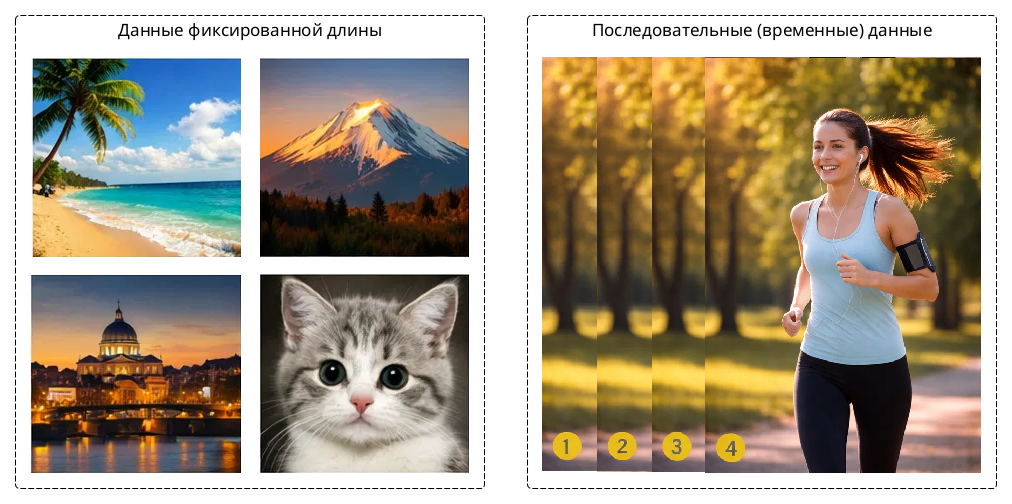

### Основные свойства


| Свойство | Данные фиксированной длины | Последовательные данные |
|--------|----------------------------|-------------------------|
| Роль порядка | Не имеет значения | Критически важен |
| Данные независимые и одинаково распределённые | Выполняется | Нарушается |
| Перемешивание данных | Допустимо | Недопустимо |
| Разбиение train/test | Произвольное | Строго по времени |
| Интерполяция | Сравнительно простая | Обычно возможна |
| Экстраполяция | Сравнительно простая | Принципиально сложная |
| Накопление ошибки | Отсутствует | Присутствует |
| Причинная структура | Неявная | Явная (каузальная) |
| Зависимость наблюдений | Отсутствует | Сильная временная |
| Типичная модель | $y = f(x)$ | $x_t = f(x_{<t})$ |

#### Типы задач с последовательностями

Данные во многих прикладных задачах представлены в виде **последовательностей**: текста, аудио, видео, временных рядов датчиков и т. д. В зависимости от того, что является входом и что требуется получить на выходе, можно выделить несколько базовых постановок задач.

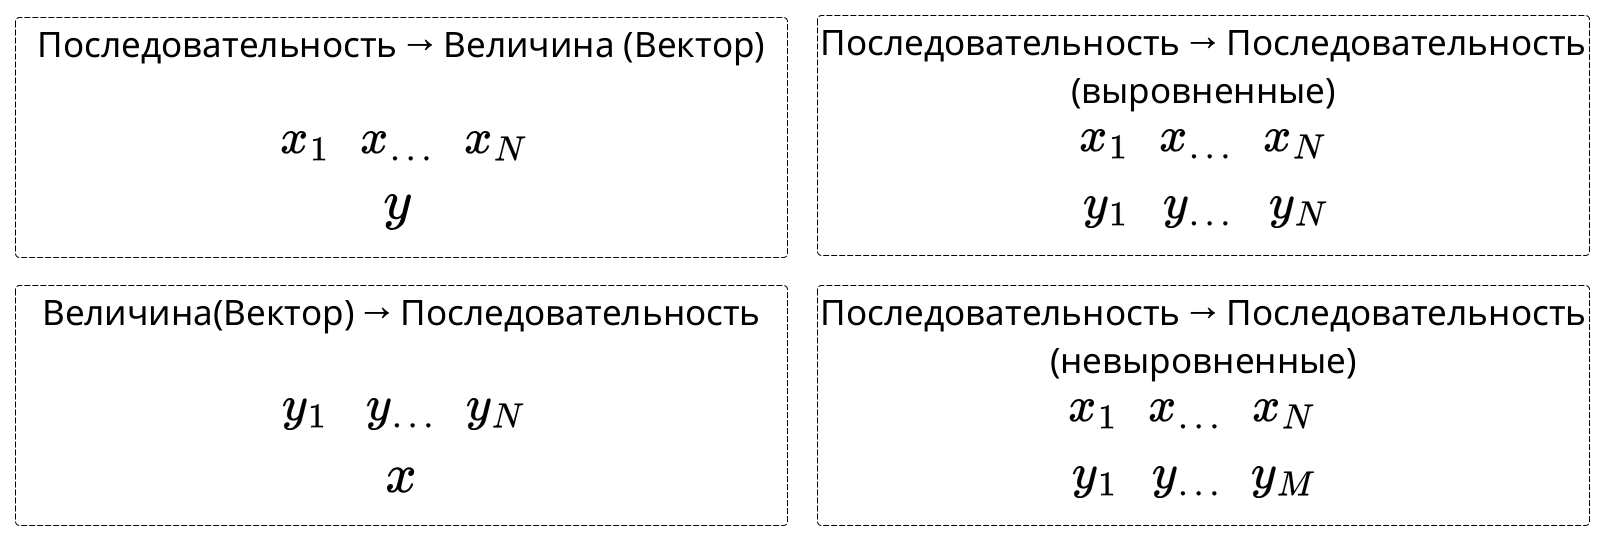

---

#### Последовательность → Величина (Sequence → Value)

##### Общая постановка
Модель получает на вход **последовательность элементов**:

$$
\mathbf{x} = (x_1, x_2, \dots, x_T),
$$

должна выдать **одно выходное значение** (скаляр или вектор фиксированной размерности), которое характеризует **всю последовательность целиком**.

Основная задача модели — **агрегировать информацию по времени** и извлечь глобальные закономерности.

##### Пример
**Анализ тональности текста:**
- вход: последовательность слов или токенов предложения;
- выход: класс тональности или числовая оценка.

##### Дополнительные примеры:
- классификация документов по теме,
- обнаружение аномалий во временных рядах,
- анализ активности пользователя по логам,
- медицинская диагностика по истории измерений.

---

#### Величина → Последовательность (Value → Sequence)

##### Общая постановка
На вход подаётся **одно значение или вектор признаков фиксированной длины**:

$$
\mathbf{x} \in \mathbb{R}^d,
$$

а на выходе требуется сгенерировать **последовательность**:

$$
\mathbf{y} = (y_1, y_2, \dots, y_{T'}),
$$

часто **переменной длины**.

Данная постановка соответствует **разворачиванию информации во времени**.

##### Пример
**Генерация описания изображения (Image Captioning):**
- вход: вектор признаков изображения (например, выход CNN);
- выход: последовательность слов — текстовое описание сцены.

##### Дополнительные примеры:
- синтез речи по тексту (TTS);
- генерация музыки по стилевому вектору;
- генерация траектории движения;
- генерация временного сигнала по заданным параметрам.

---

#### 3. Последовательность → Последовательность (Sequence → Sequence, Seq2Seq)

##### Общая постановка
Модель принимает входную последовательность:

$$
(x_1, \dots, x_T),
$$

преобразует её в выходную последовательность:

$$
(y_1, \dots, y_{T'}),
$$

где длины последовательностей могут совпадать или различаться.

Это наиболее **общий и универсальный класс задач** для моделей последовательностей.

---

##### 3.1. Выровненные Seq2Seq-задачи (aligned)

###### Определение
Вход и выход **синхронизированы по времени**: каждому элементу входной последовательности соответствует ровно один элемент выходной последовательности.

$$
T = T', \quad y_t \leftrightarrow x_t.
$$

###### Пример
**Частеречная разметка (Part-of-Speech tagging):**
- вход: последовательность слов;
- выход: последовательность грамматических тегов той же длины.

###### Дополнительные примеры:
- распознавание именованных сущностей,
- посимвольная коррекция ошибок,
- классификация каждого кадра видео,
- сегментация временных рядов.

---

#### 3.2. Невыровненные Seq2Seq-задачи (unaligned)

#### Определение
Между входной и выходной последовательностями **нет прямого соответствия по времени**.  
Длины последовательностей, как правило, различаются, а соответствие является **скрытым**.

$$
T \neq T', \quad \text{явного выравнивания нет.}
$$

#### Примеры:
- машинный перевод,
- описание видео,
- распознавание речи,
- распознавание текста.

---

### Авторегрессионные модели. Модели Маркова

Прежде чем вводить специализированные нейронные сети, предназначенные для работы с данными, имеющими последовательную структуру, рассмотрим реальные последовательные данные и сформируем базовые интуиции и статистические инструменты.

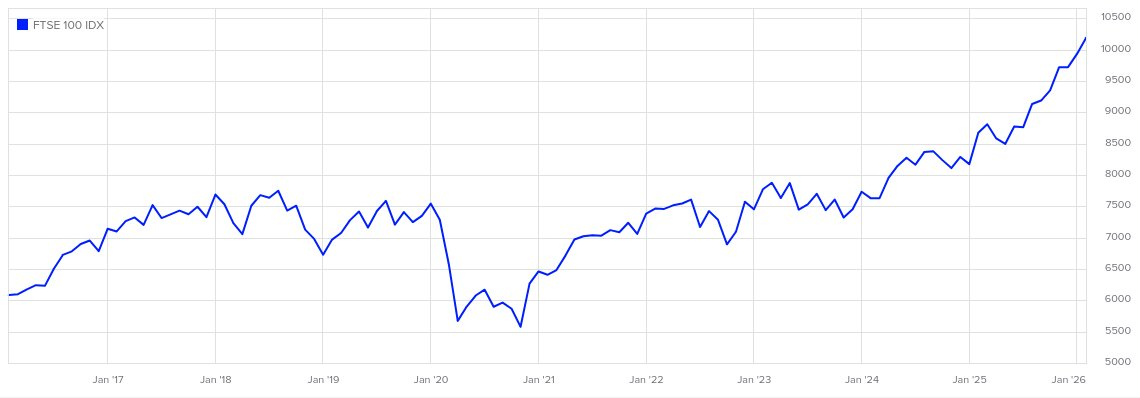

Для наглядности мы рассмотрим данные о стоимости акций индекса `FTSE 100`. На каждом временном шаге `t` мы наблюдаем цену $x_t$ индекса в этот момент времени.

 #### Авторегрессионные модели

Предположим, что трейдер хочет совершать краткосрочные сделки, стратегически входя в индекс или выходя из него в зависимости от того, ожидает ли он роста или падения индекса на следующем временном шаге. При отсутствии каких-либо дополнительных признаков (новостей, финансовой отчётности и т. п.) единственным доступным сигналом для предсказания следующего значения является история цен до текущего момента. Таким образом, трейдера интересует распределение вероятностей, которое описывает возможные значения индекса на следующем временном шаге:

\begin{equation}
p(x_{t+1} \mid x_1, \ldots, x_t).
\end{equation}

Хотя оценка полного распределения для непрерывной случайной величины является сложной задачей, на практике часто достаточно сосредоточиться на нескольких ключевых статистиках распределения, прежде всего на математическом ожидании и дисперсии. Одной из простейших стратегий оценки условного математического ожидания

\begin{equation}
\mathbb{E}\bigl[x_{t+1} \mid x_1, \ldots, x_t\bigr]
\end{equation}
является применение линейной регрессии.

Модели, в которых значение сигнала регрессируется по предыдущим значениям этого же сигнала, естественным образом называются `авторегрессионными моделями`. Однако здесь возникает фундаментальная проблема: число входов зависит от времени $t$. Иными словами, количество входных признаков увеличивается по мере накопления данных. Если рассматривать исторические данные как обучающую выборку, то каждый пример будет иметь разное число признаков. На практике часто используется несколько стратегий.

Во-первых, можно предположить: хотя длинные последовательности и доступны, для предсказания ближайшего будущего нет необходимости учитывать всю историю. В этом случае модель можно условить только на окно фиксированной длины $\tau $, используя наблюдения:
$$
x_{t-\tau+1}, \ldots, x_t.
$$
Преимущество такого подхода состоит в том, что размер входного вектора становится фиксированным (по крайней мере, при $t \ge \tau $), что позволяет применять стандартные линейные модели и глубокие нейронные сети.

Во-вторых, можно разрабатывать модели, которые поддерживают некоторое сводное представление прошлых наблюдений. Пусть $ h_t $ обозначает латентное состояние, агрегирующее информацию о прошлом. Тогда модель одновременно выполняет предсказание
$$
x_{t+1} \sim p(x_{t+1} \mid h_t)
$$
и обновление состояния

\begin{equation}
h_{t+1} = f(h_t, x_t).
\end{equation}

Поскольку переменная $ h_t $ непосредственно не наблюдается, такие модели называются `латентными авторегрессионными моделями или авторегрессионные модели со скрытым состоянием`.

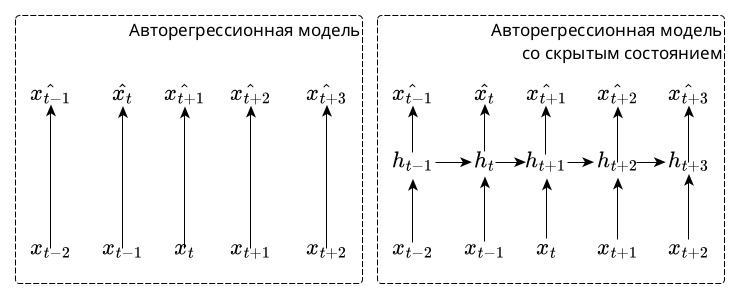

#### Марковские модели

Иногда нас интересует оценка совместной вероятности всей последовательности целиком. Такая постановка характерна для задач, где данные представляют собой последовательности дискретных токенов. В общем случае соответствующие вероятностные функции называют `моделями последовательностей`. Они позволяют не только оценивать правдоподобие наблюдаемых последовательностей, но и генерировать новые, а также находить наиболее вероятные продолжения.

Совместное распределение последовательности можно свести к авторегрессионному предсказанию, разложив его в произведение условных распределений с помощью цепного правила вероятностей:

\begin{equation}
p(x_1, \ldots, x_T)
=
\prod_{t=1}^{T} p(x_t \mid x_1, \ldots, x_{t-1}).
\end{equation}

В случае дискретных данных такая модель представляет собой `вероятностный классификатор`, который на каждом шаге выдаёт распределение вероятностей следующего токена с учётом предыдущего контекста.

Часто оказывается избыточным условие на всю историю последовательности. Если для предсказания достаточно учитывать только последние $\tau$ шагов:
$$
p(x_t \mid x_1,\ldots,x_{t-1}) = p(x_t \mid x_{t-1}, \ldots, x_{t-\tau}),
$$
то говорят, что последовательность удовлетворяет `марковскому условию` порядка $\tau$. При $\tau = 1$ получается `марковская модель первого порядка`, а при $\tau = k$ — `марковская модель порядка` $k$. В простейшем случае первого порядка совместное распределение факторизуется как

\begin{equation}
p(x_1, \ldots, x_T)
=
\prod_{t=1}^{T} p(x_t \mid x_{t-1}).
\end{equation}

На практике марковское предположение часто используется даже тогда, когда оно выполняется лишь приближённо. Увеличение длины контекста действительно даёт дополнительную информацию, однако выигрыш быстро уменьшается, тогда как вычислительная и статистическая сложность существенно растёт. Поэтому модели с ограниченным порядком $k$ представляют собой разумный компромисс.

Для дискретных данных классическая марковская модель сводится к подсчёту частот появления токенов в каждом контексте и оценке условных вероятностей:

$$
p(x_t \mid x_{t-1}, \ldots, x_{t-k}).
$$

В этом случае наиболее вероятную последовательность можно эффективно находить с помощью методов динамического программирования.


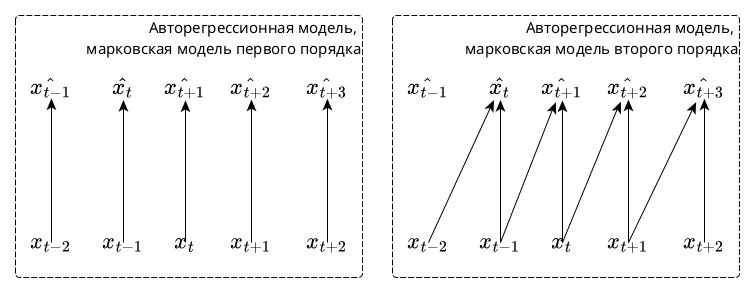

#### Порядок декодирования

Может возникнуть вопрос, почему факторизация последовательности обычно задаётся в виде цепочки условных вероятностей, развёрнутой `слева направо`. Почему бы не использовать обратный или произвольный порядок? Формально в этом нет ошибки. Развёртывание справа налево также даёт корректную факторизацию:

\begin{equation}
p(x_1, \ldots, x_T) = \prod_{t=T}^{1} p(x_t \mid x_{t+1}, \ldots, x_T).
\end{equation}

Тем не менее на практике предпочтение часто отдаётся естественному порядку следования элементов последовательности. Во-первых, такой порядок более интуитивен: при обработке данных мы обычно рассуждаем в терминах «что произойдёт дальше», опираясь на уже наблюдённый контекст. Это упрощает как интерпретацию моделей, так и анализ их поведения.

Во-вторых, факторизация в естественном порядке позволяет легко расширять последовательность. Чтобы перейти от вероятности длины $T$ к длине $T+1$, достаточно домножить её на условную вероятность нового элемента:

$$
p(x_1, \ldots, x_{T+1}) = p(x_1, \ldots, x_T)\, p(x_{T+1} \mid x_1, \ldots, x_T).
$$

Это даёт возможность работать с последовательностями произвольной длины в рамках одной и той же модели.

В-третьих, предсказание ближайших элементов, как правило, проще и точнее, чем предсказание элементов в удалённых позициях. Хотя все порядки факторизации формально допустимы, они не обязательно приводят к задачам одинаковой сложности. Это особенно важно для данных с причинной структурой, где считается, что будущее не может влиять на прошлое. В таких случаях предсказание $x_{t+1}$ по $x_t$ часто оказывается существенно проще, чем обратная задача.

### Рекуррентные нейронные сети: `RNN`, `LSTM`, `GRU`, `xLSTM`

In [ ]:
B, T, D, H = 4, 7, 10, 16
x = torch.randn(B, T, D)

In [ ]:
# ----------------------------
# Utilities
# ----------------------------
@dataclass
class SeqOut:
    y  : torch.Tensor # (B, T, H)  hidden outputs per time step
    h_T: torch.Tensor # last hidden state (B, H)
    c_T: torch.Tensor | None = None  # last cell state (B, H) if applicable

def _init_state(batch_size: int, hidden_size: int, device, dtype):
    return torch.zeros(batch_size, hidden_size, device=device, dtype=dtype)

#### `RNN` — Recurrent Meural Network

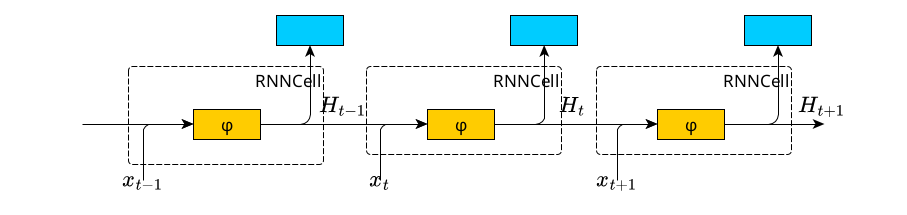

Рекуррентная нейронная сеть обрабатывает последовательность $\{x_t\}_{t=1}^T$ по шагам, передавая скрытое состояние от момента времени $t-1$ к моменту $t$.

Математическая модель классической `RNN` имеет вид:

\begin{equation}
h_t = \phi\left(W_x x_t + W_h h_{t-1} + b\right),
\end{equation}
\begin{equation}
y_t = W_y h_t + c,
\end{equation}

где $x_t$ — входной вектор, $h_t$ — скрытое состояние, $y_t$ — выход сети, $\phi(\cdot)$ — нелинейная функция активации.

### Обратное распространение ошибки во времени

Если вспомнить рассмотрение прямого и обратного распространения по вычислительным графам при изучении многослойных перцептронов, то прямое распространение в `RNN` не вызывает особых трудностей. Применение обратного распространения ошибки в рекуррентных сетях называется `обратным распространением ошибки во времени` (Backpropagation Through Time, BPTT). Этот метод требует развёрнуть (unroll) вычислительный граф `RNN` по временным шагам. Развёрнутая `RNN` эквивалентна полносвязной нейронной сети с тем отличием, что одни и те же параметры повторяются на каждом временном шаге. После этого, как и в любой прямой нейронной сети, можно применять `правило дифференцирования сложной функции` (chain rule) для распространения градиентов. Градиент по каждому параметру вычисляется как сумма вкладов со всех временных шагов, в которых этот параметр используется. Работа с такими «связанными» весами уже знакома по свёрточным нейронным сетям.

Существенные сложности возникают из-за большой длины последовательностей. В реальных задачах нередко встречаются последовательности длиной более тысячи токенов, что создаёт проблемы как с точки зрения вычислений (память), так и с точки зрения оптимизации (числовая нестабильность). Сигнал с первого временного шага проходит  более чем через тысячу матричных умножений, прежде чем повлиять на выход, и ещё столько же операций требуется при вычислении градиентов.

<div style="display:flex; justify-content:center;">
  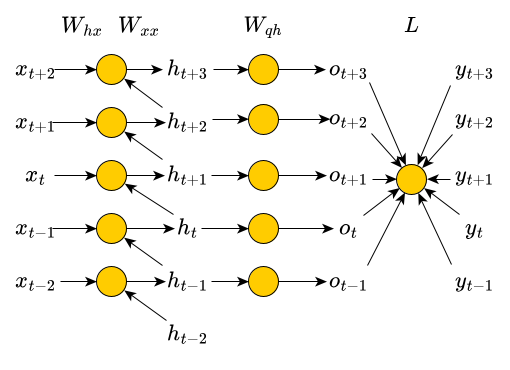
</div>

#### Анализ градиентов в рекуррентных нейронных сетях

Рассмотрим общую модель рекуррентной нейронной сети, не акцентируя внимание на различиях между скалярами, векторами и матрицами, поскольку наша цель — сформировать интуитивное понимание механизма распространения градиентов.

Пусть $h_t$ обозначает скрытое состояние, $x_t$ — вход, а $o_t$ — выход на временном шаге $t$. Динамика `RNN` задаётся уравнениями:
\begin{equation}
h_t = \phi(W_h h_{t-1} + U x_t),
\end{equation}
\begin{equation}
o_t = \psi(W_o h_t),
\end{equation}
где $W_h$ — матрица рекуррентных весов, $U$ — матрица входных весов, $W_o$ — веса выходного слоя, а функции $\phi(\cdot)$ и $\psi(\cdot)$ задают нелинейные преобразования.

Функция потерь агрегирует ошибки на всех временных шагах:
\begin{equation}
L = \sum_{t=1}^{T} \ell(o_t, y_t).
\end{equation}

Градиент функции потерь по рекуррентным весам вычисляется согласно правилу дифференцирования сложной функции:
\begin{equation}
\frac{\partial L}{\partial W_h}
=
\sum_{t=1}^{T}
\frac{\partial L}{\partial h_t}
\frac{\partial h_t}{\partial W_h}.
\end{equation}

Основная сложность заключается в вычислении величины $\partial L / \partial h_t$, поскольку скрытое состояние $h_t$ влияет не только на текущий выход, но и на все последующие состояния. Полная производная удовлетворяет рекуррентному соотношению:
\begin{equation}
\frac{\partial L}{\partial h_t}
=
\frac{\partial L}{\partial o_t}
\frac{\partial o_t}{\partial h_t}
+
\frac{\partial L}{\partial h_{t+1}}
\frac{\partial h_{t+1}}{\partial h_t}.
\end{equation}

Развёртывание этой рекурсии по времени приводит к выражению:
\begin{equation}
\frac{\partial L}{\partial h_t}
=
\sum_{k=t}^{T}
\left(
\prod_{i=t+1}^{k}
\frac{\partial h_i}{\partial h_{i-1}}
\right)
\frac{\partial L}{\partial o_k}
\frac{\partial o_k}{\partial h_k},
\end{equation}
где явно появляется произведение якобианов перехода скрытого состояния между временными шагами.

---

Для более наглядного анализа рассмотрим линейную `RNN` без нелинейностей:
\begin{equation}
h_t = W_h h_{t-1},
\end{equation}
где вход и выход временно опущены, поскольку они не меняют принципиального характера рассуждений.

В этом случае якобиан перехода упрощается:
\begin{equation}
\frac{\partial h_t}{\partial h_{t-1}} = W_h,
\end{equation}
выражение для градиента принимает вид:
\begin{equation}
\frac{\partial L}{\partial h_t}
=
\sum_{k=t}^{T}
W_h^{\,k-t}
\frac{\partial L}{\partial h_k}.
\end{equation}

Норма произведения степеней матрицы $W_h$ в первом приближении определяется её спектральным радиусом:
\begin{equation}
\left\| W_h^{\,n} \right\|
\approx
\rho(W_h)^{\,n},
\end{equation}
где
\begin{equation}
\rho(W_h) = \max_i |\lambda_i|
\end{equation}
— максимальный по модулю собственный корень матрицы $W_h$.

---

#### Выводы о спектральном радиусе

Из полученных выражений следует фундаментальное свойство рекуррентных сетей:
- если $\rho(W_h) < 1$, то
$
\left\| \frac{\partial L}{\partial h_t} \right\|
\xrightarrow[T \to \infty]{}
0
$
и градиенты экспоненциально затухают;
- если $\rho(W_h) > 1$, то
$
\left\| \frac{\partial L}{\partial h_t} \right\|
\xrightarrow[T \to \infty]{}
\infty
$
и градиенты экспоненциально растут;
- если $\rho(W_h) \approx 1$, система находится на границе устойчивости, где градиенты в среднем сохраняют масштаб, но остаются чувствительными к длине последовательности.

Таким образом, проблема исчезающих и взрывающихся градиентов является прямым следствием спектральных свойств рекуррентной матрицы весов и фундаментальным ограничением классических `RNN` при работе с длинными последовательностями.

#### Стратегии работы с длинными последовательностями

- Полное обратное распространение.
Вычисление полной суммы практически не используется: оно крайне медленно и численно нестабильно. Малые изменения в начальных условиях могут приводить к непропорционально большим изменениям результата.

- Обрезка по времени.
На практике сумму обрезают после фиксированного числа шагов $\tau$. Это называется `усечённым обратным распространением ошибки во времени` (truncated BPTT). Такой подход даёт приближение истинного градиента и смещает модель в сторону учёта краткосрочных зависимостей, что часто повышает устойчивость обучения.

- Случайная обрезка.
Возможна и стохастическая стратегия, при которой длина обратного распространения является случайной величиной с корректным математическим ожиданием. В этом случае длинные цепочки встречаются редко, но получают больший вес.

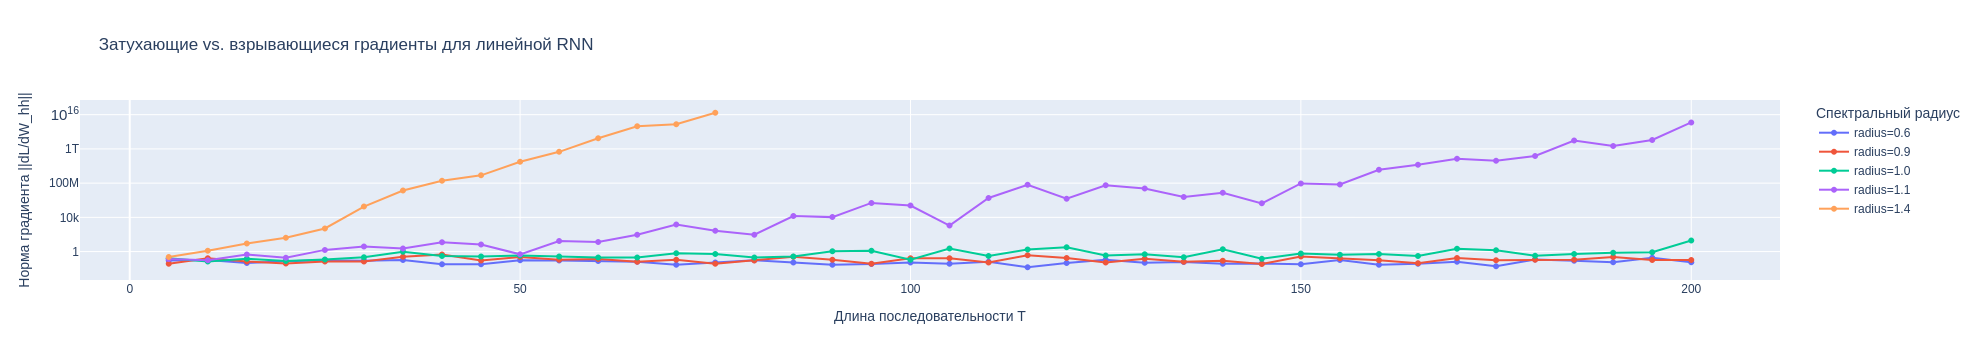

In [ ]:
# -----------------------------
# Демонстрационный пример RNN
#   h_t = W_hh h_{t-1} + W_hx x_t
#   o_t = W_oh h_t
# Loss (только последний шаг)
#   L = 0.5 * ||o_T - y||^2
# -----------------------------

def make_W_hh_with_radius(hidden_dim: int, radius: float, device: str):
    """
    Создаём W_hh с контролируемым спектральным радиусом (примерно равным radius).
    Конструкция: W = Q D Q^{-1}, где Q ортогональна, D диагональна.
    """
    A    = torch.randn(hidden_dim, hidden_dim, device=device)
    Q, _ = torch.linalg.qr(A)  # orthogonal

    eig = (2 * torch.rand(hidden_dim, device=device) - 1.0) * radius
    eig[0] = radius  # Фиксируем максимум по модулю
    D = torch.diag(eig)

    W = Q @ D @ torch.linalg.inv(Q)
    return W

def run_once(T: int, hidden_dim: int, radius: float, x_scale: float = 0.2, clip_max_norm=None):
    W_hh = make_W_hh_with_radius(hidden_dim, radius, device).requires_grad_(True)
    W_hx = (0.1 * torch.randn(hidden_dim, 1, device=device)).requires_grad_(True)
    W_oh = (0.1 * torch.randn(1, hidden_dim, device=device)).requires_grad_(True)

    x = x_scale * torch.randn(T, 1, device=device)
    y = torch.tensor([[1.0]], device=device)

    h = torch.zeros(hidden_dim, 1, device=device)
    for t in range(T):
        h = W_hh @ h + W_hx @ x[t:t+1].T
    oT = W_oh @ h

    loss = 0.5 * (oT - y).pow(2).sum()
    loss.backward()

    if clip_max_norm is not None:
        torch.nn.utils.clip_grad_norm_([W_hh, W_hx, W_oh], max_norm=clip_max_norm)

    g_hh = W_hh.grad.detach().norm().item()
    g_hx = W_hx.grad.detach().norm().item()
    g_oh = W_oh.grad.detach().norm().item()

    return loss.item(), g_hh, g_hx, g_oh

def sweep(T_list, radii, hidden_dim=32, clip_max_norm=None):
    results = {}
    for r in radii:
        gnorms = []
        for T in T_list:
            _, g_hh, _, _ = run_once(T, hidden_dim, r, x_scale=0.2, clip_max_norm=clip_max_norm)
            gnorms.append(g_hh)
        results[r] = gnorms
    return results

# -----------------------------
# Эксперимент и график
# -----------------------------
T_list = list(range(5, 201, 5))
radii  = [0.6, 0.9, 1.0, 1.1, 1.4]  # <1: затухание, >1: взрыв

# Без клиппинга
results = sweep(T_list, radii, hidden_dim=32, clip_max_norm=None)

fig = go.Figure()
for r in radii:
    fig.add_trace(go.Scatter(
        x=T_list,
        y=results[r],
        mode="lines+markers",
        name=f"radius={r}"
    ))

fig.update_layout(
    title="Затухающие vs. взрывающиеся градиенты для линейной RNN",
    xaxis_title="Длина последовательности T",
    yaxis_title="Норма градиента ||dL/dW_hh||",
    legend_title="Спектральный радиус",
)
fig.update_yaxes(type="log")  # Лог шкала по Y

fig.show()

# -----------------------------
# (Опционально) С клиппингом
# -----------------------------
# results_clip = sweep(T_list, radii, hidden_dim=32, clip_max_norm=1.0)
# fig2 = go.Figure()
# for r in radii:
#     fig2.add_trace(go.Scatter(x=T_list, y=results_clip[r], mode="lines+markers", name=f"radius={r}"))
# fig2.update_layout(
#     title="Same experiment with gradient clipping (max_norm=1.0)",
#     xaxis_title="Sequence length T",
#     yaxis_title="Clipped gradient norm ||dL/dW_hh||",
# )
# fig2.update_yaxes(type="log")
# fig2.show()


#### Итоги

- Обратное распространение ошибки во времени представляет собой применение стандартного `backpropagation` к моделям с рекуррентным скрытым состоянием.
- Для вычислительной эффективности и числовой устойчивости необходимо использовать усечение по времени.
- Высокие степени матриц перехода приводят к исчезающим или взрывающимся градиентам.
- Для ускорения вычислений промежуточные значения кешируются и переиспользуются при обратном проходе.


In [ ]:
# ============================================================
# 1) Vanilla RNN (tanh)
# ============================================================
class RNNCell(nn.Module):
    def __init__(self, input_size: int, hidden_size: int):
        super().__init__()
        self.input_size  = input_size
        self.hidden_size = hidden_size

        self.W_x = nn.Linear(input_size, hidden_size, bias=True)
        self.W_h = nn.Linear(hidden_size, hidden_size, bias=False)

    def forward(self, x_t: torch.Tensor, h_prev: torch.Tensor) -> torch.Tensor:
        # x_t: (B, D), h_prev: (B, H)
        h_t = torch.tanh(self.W_x(x_t) + self.W_h(h_prev))
        return h_t

class RNN(nn.Module):
    def __init__(self, input_size: int, hidden_size: int):
        super().__init__()
        self.cell = RNNCell(input_size, hidden_size)

    def forward(self, x: torch.Tensor, h0: torch.Tensor | None = None) -> SeqOut:
        # x: (B, T, D)
        B, T, _ = x.shape
        device, dtype = x.device, x.dtype

        h_t = h0 if h0 is not None else _init_state(B, self.cell.hidden_size, device, dtype)

        ys = []
        for t in range(T):
            h_t = self.cell(x[:, t, :], h_t)
            ys.append(h_t.unsqueeze(1))

        y = torch.cat(ys, dim=1)  # (B, T, H)
        return SeqOut(y=y, h_T=h_t, c_T=None)

In [ ]:
rnn_model = RNN(D, H)
y_rnn   = rnn_model(x)
print("RNN:  ", y_rnn.y.shape, y_rnn.h_T.shape, y_rnn.c_T)

RNN:   torch.Size([4, 7, 16]) torch.Size([4, 16]) None


#### `LSTM` — Long Short-Term Memory

#### `input gate`, `forget gate`, `output gate` (входной, забывающий и выходной вентили)

Данные, поступающие на вход вентилей `LSTM`, включают `вход на текущем временном шаге` и `скрытое состояние с предыдущего временного шага`. Три полносвязных слоя с сигмоидной функцией активации вычисляют значения `input gate`, `forget gate` и `output gate`. Благодаря сигмоидной активации все значения этих трёх вентилей лежат в диапазоне $(0, 1)$. Кроме того, используется `input node`, который обычно вычисляется с помощью функции активации $\tanh$.

Интуитивно:

- `input gate`  определяет, какая часть значения входного узла добавляется к внутреннему состоянию `memory cell` (ячейки памяти);
- `forget gate` определяет, следует ли сохранить текущее значение памяти или очистить его;
- `output gate` определяет, влияет ли состояние ячейки памяти на выход на текущем временном шаге.

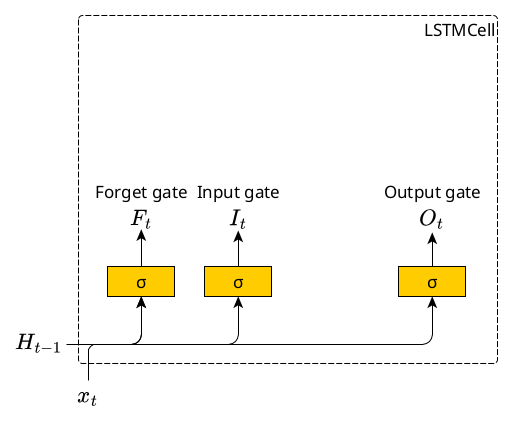

Математически предположим, что число скрытых нейронов равно $h$, размер батча равен $n$, а число входных признаков равно $d$. Тогда вход имеет размерность$X_t \in \mathbb{R}^{n \times d}$, а скрытое состояние предыдущего временного шага — $H_{t-1} \in \mathbb{R}^{n \times h}$.

Соответственно, вентили на временном шаге $t$ определяются следующим образом:
входной вентиль $I_t$, вентиль забывания $F_t$ и выходной вентиль $O_t$:

\begin{equation}
\begin{aligned}
I_t &= \sigma\!\left(X_t W_{xi} + H_{t-1} W_{hi} + b_i\right), \\
F_t &= \sigma\!\left(X_t W_{xf} + H_{t-1} W_{hf} + b_f\right), \\
O_t &= \sigma\!\left(X_t W_{xo} + H_{t-1} W_{ho} + b_o\right),
\end{aligned}
\end{equation}

где $W_{x*}$ и $W_{h*}$ — матрицы весов, а $b_*$ — векторы смещений.
Следует отметить, что при суммировании используется механизм `broadcasting`.
Сигмоидная функция $\sigma(\cdot)$ отображает входные значения в интервал $(0, 1)$.


#### input node (обновление памяти)

Далее мы переходим к построению `memory cell` (ячейки памяти). Поскольку действие различных вентилей ещё не было полностью определено, сначала введём `input node` (обновление памяти), обозначаемый как $\tilde{C}_t$. Его вычисление аналогично вычислению трёх вентилей, описанных выше, однако в качестве функции активации используется функция с диапазоном значений $(-1, 1)$, как правило, $\tanh$.

Это приводит к следующему уравнению на временном шаге $t$:

\begin{equation}
\tilde{C}_t =
\tanh\!\left(
X_t W_{xc} + H_{t-1} W_{hc} + b_c
\right),
\end{equation}
где $W_{xc}$ и $W_{hc}$ — матрицы весов, а $b_c$ — вектор смещений.

Входной узел $\tilde{C}_t$ представляет собой `обновление памяти`, которое может быть добавлено к текущему состоянию `memory cell` (ячейки памяти). То, в какой степени это значение будет использовано, определяется входным вентилем $I_t$.

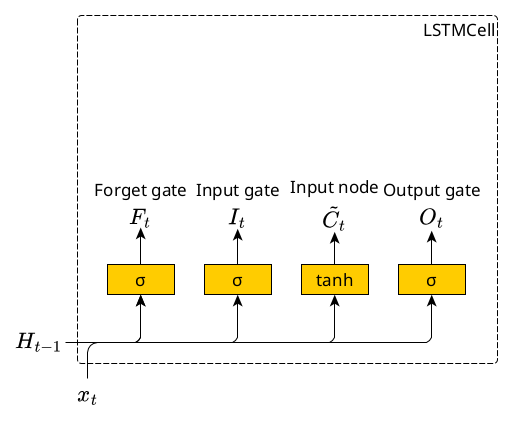

#### Внутреннее состояние `cell memory`

В `LSTM` `input gate` определяет, в какой степени новая информация учитывается через $\tilde{C}_t$, а `forget gate` — какую часть предыдущего внутреннего состояния ячейки памяти следует сохранить.
Используя поэлементное произведение (произведение Адамара), получаем следующее уравнение обновления:

\begin{equation}
C_t = F_t \odot C_{t-1} + I_t \odot \tilde{C}_t.
\end{equation}

Если `forget gate` всегда равен $1$, а `input gate` всегда равен $0$, то внутреннее состояние ячейки памяти остаётся неизменным и передаётся без изменений на каждый последующий временной шаг. Однако наличие входного
вентиля и вентиля забывания даёт модели гибкость: она может `обучаться` тому, когда следует сохранять значение памяти, а когда — модифицировать его в ответ на новые входные данные.

На практике такая архитектура существенно ослабляет проблему исчезающих градиентов и приводит к моделям, которые значительно легче обучать, особенно при работе с наборами данных, содержащими длинные последовательности.

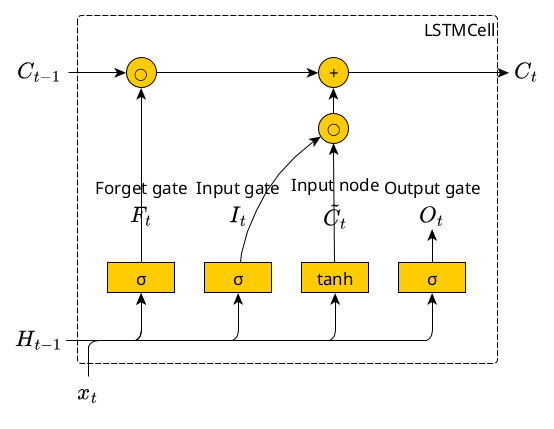

#### Hidden state (скрытое состояние)

В конце необходимо определить, как вычисляется выход ячейки памяти, то есть скрытое состояние, которое «видят» остальные слои сети. Именно здесь вступает в действие `output gate`. В архитектуре `LSTM` сначала к `memory cell` (внутреннему состоянию ячейки памяти) применяется нелинейное преобразование, после чего выполняется поэлементное умножение на `output gate`. Это гарантирует, что значения скрытого состояния всегда лежат в интервале `(−1,1)`:

\begin{equation}
\mathbf{H}_t = \mathbf{O}_t \odot \tanh\!\left(\mathbf{C}_t\right).
\end{equation}

Когда значение `output gate` близко к 1, `memory cell` (внутреннее состояние ячейки памяти) беспрепятственно влияет на последующие слои сети. Напротив, когда `output gate` принимает значения, близкие к 0, текущее содержимое памяти практически не воздействует на другие слои сети на данном временном шаге. Важно отметить, что `memory cell` (ячейка памяти) может накапливать информацию на протяжении многих временных шагов, не оказывая влияния на остальную часть сети (пока `output gate` остаётся близким к 0), а затем внезапно начать влиять на сеть на одном из последующих шагов времени, когда значение `output gate` (выходного вентиля) переключается из области, близкой к 0, в область, близкую к 1.

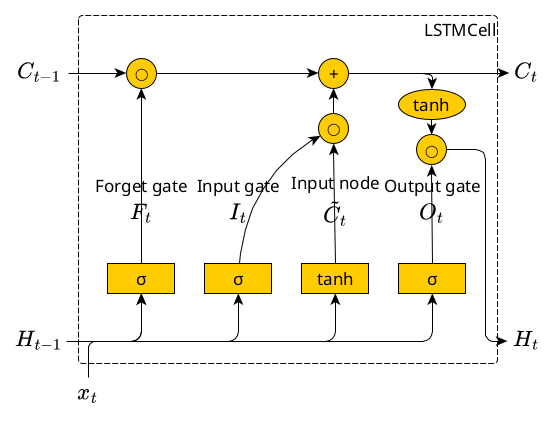

#### Полная система уравнений `LSTM`

\begin{equation}
\begin{aligned}
I_t &= \sigma\!\left(X_t W_{xi} + H_{t-1} W_{hi} + b_i\right), \\
F_t &= \sigma\!\left(X_t W_{xf} + H_{t-1} W_{hf} + b_f\right), \\
O_t &= \sigma\!\left(X_t W_{xo} + H_{t-1} W_{ho} + b_o\right), \\
C_t &= F_t \odot C_{t-1} + I_t \odot \tilde{C}_t, \\
\mathbf{H}_t &= \mathbf{O}_t \odot \tanh\!\left(\mathbf{C}_t\right).
\end{aligned}
\end{equation}

In [ ]:
# ============================================================
# 2) LSTM
# ============================================================
class LSTMCell(nn.Module):
    def __init__(self, input_size: int, hidden_size: int):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size

        # We'll compute all gates in one affine: [f, i, g, o]
        self.x_proj = nn.Linear(input_size, 4 * hidden_size, bias=True)
        self.h_proj = nn.Linear(hidden_size, 4 * hidden_size, bias=False)

    def forward(
        self, x_t: torch.Tensor, h_prev: torch.Tensor, c_prev: torch.Tensor
    ) -> tuple[torch.Tensor, torch.Tensor]:
        # x_t: (B, D), h_prev,c_prev: (B,H)
        gates = self.x_proj(x_t) + self.h_proj(h_prev)  # (B, 4H)
        f, i, g, o = gates.chunk(4, dim=-1)

        f = torch.sigmoid(f)
        i = torch.sigmoid(i)
        g = torch.tanh(g)
        o = torch.sigmoid(o)

        c_t = f * c_prev + i * g
        h_t = o * torch.tanh(c_t)
        return h_t, c_t


class LSTM(nn.Module):
    def __init__(self, input_size: int, hidden_size: int):
        super().__init__()
        self.cell = LSTMCell(input_size, hidden_size)

    def forward(
        self,
        x: torch.Tensor,
        h0: torch.Tensor | None = None,
        c0: torch.Tensor | None = None
    ) -> SeqOut:
        # x: (B,T,D)
        B, T, _ = x.shape
        device, dtype = x.device, x.dtype

        h_t = h0 if h0 is not None else _init_state(B, self.cell.hidden_size, device, dtype)
        c_t = c0 if c0 is not None else _init_state(B, self.cell.hidden_size, device, dtype)

        ys = []
        for t in range(T):
            h_t, c_t = self.cell(x[:, t, :], h_t, c_t)
            ys.append(h_t.unsqueeze(1))

        y = torch.cat(ys, dim=1)
        return SeqOut(y=y, h_T=h_t, c_T=c_t)

In [ ]:
lstm_model = LSTM(D, H)
y_lstm     = lstm_model(x)
print("LSTM: ", y_lstm.y.shape, y_lstm.h_T.shape, y_lstm.c_T.shape)

LSTM:  torch.Size([4, 7, 16]) torch.Size([4, 16]) torch.Size([4, 16])


#### Общий вывод

Хотя модели `LSTM` были предложены ещё в 1997 году, широкую известность они получили после ряда успешных выступлений в соревнованиях по прогнозированию в середине 2000-х годов. Начиная примерно с 2011 года и вплоть до появления моделей `Transformer` в 2017 году `LSTM` оставались доминирующей архитектурой для обучения на последовательных данных. Более того, даже архитектуры `Transformer` во многом опираются на идеи проектирования, впервые реализованные в `LSTM`. Архитектура `LSTM` включает три типа вентилей: входные, вентили забывания и выходные, которые управляют потоком информации внутри модели. Выход скрытого слоя `LSTM` состоит из двух компонентов: скрытого состояния и внутреннего состояния ячейки памяти. При этом только скрытое состояние передаётся в выходной слой, тогда как внутреннее состояние ячейки памяти остаётся полностью внутренним.

Благодаря такой организации внутреннего состояния и механизмам управления потоком информации, `LSTM` способны существенно ослаблять проблемы исчезающих и взрывающихся градиентов при обучении на длинных последовательностях.

#### `GRU` — Gated Recurrent Unit

По мере того как рекуррентные нейронные сети и, в частности, архитектура `LSTM` быстро набирали популярность в 2010-е годы, ряд исследователей начал экспериментировать с упрощёнными архитектурами. Целью этих работ было сохранить ключевую идею наличия внутреннего состояния и мультипликативных механизмов управления, одновременно ускорив вычисления.

`Gated Recurrent Unit (GRU)` предложила более компактную и упрощённую версию ячейки памяти `LSTM`, которая во многих задачах демонстрирует сопоставимое качество, обладая при этом преимуществом более высокой вычислительной эффективности.

#### Reset Gate, Update Gate (вентилем сброса, вентилем обновления)

В данной архитектуре три вентиля `LSTM` заменяются двумя: reset gate (вентилем сброса) и update gate (вентилем обновления). Как и в `LSTM`, для этих вентилей используется сигмоидальная функция активации, что ограничивает их значения интервалом
(0,1). Интуитивно вентиль сброса определяет, какую часть предыдущего состояния следует сохранить. Аналогично вентиль обновления позволяет контролировать, в какой степени новое состояние является копией старого.

Математически для временного шага $t$ пусть вход $X_t \in \mathbb{R}^{n \times d}$ представляет собой мини-пакет из $n$ примеров с $d$ входными признаками, а скрытое состояние предыдущего шага $H_{t-1} \in \mathbb{R}^{n \times h}$ имеет размерность $h$, соответствующую числу скрытых нейронов. Тогда вентиль сброса и вентиль обновления вычисляются следующим образом:
\begin{equation}
\begin{aligned}
R_t &= \sigma\!\left(X_t W_{xr} + H_{t-1} W_{hr} + b_r\right), \\
Z_t &= \sigma\!\left(X_t W_{xz} + H_{t-1} W_{hz} + b_z\right),
\end{aligned}
\tag{10.2.1}
\end{equation}
где $\sigma(\cdot)$ — сигмоидальная функция активации,  
$W_{xr}, W_{xz} \in \mathbb{R}^{d \times h}$ и $W_{hr}, W_{hz} \in \mathbb{R}^{h \times h}$ — обучаемые матрицы весов,  
$b_r, b_z \in \mathbb{R}^{h}$ — векторы смещений.


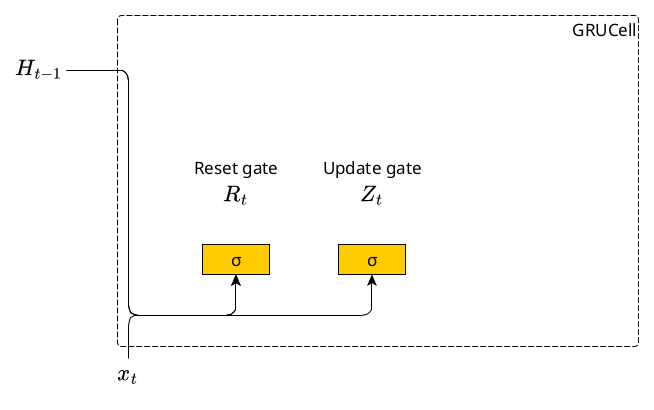

#### Candidate Hidden State (обновление скрытого состояния)

Далее мы интегрируем `reset gate` (вентиль сброса) с обычным `update gate` (механизмом обновления), что приводит к следующему выражению для `candidate hidden state` на временном шаге~$t$:

\begin{equation}
\tilde{H}_t = \tanh\!\left( X_t W_{xh} + \left(R_t \odot H_{t-1}\right) W_{hh} + b_h \right).
\end{equation}

Здесь $W_{xh}$ и $W_{hh}$ — обучаемые весовые параметры, $b_h$ — вектор смещений, а символ $\odot$ обозначает поэлементное (хадемардово) произведение. В качестве функции активации используется гиперболический тангенс $\tanh(\cdot)$. Полученное состояние является *кандидатным*, поскольку на данном этапе ещё не учитывается действие вентиля обновления. Влияние предыдущих скрытых состояний теперь может быть ослаблено за счёт поэлементного умножения $R_t \odot H_{t-1}$. Если значения вентиля сброса близки к $1$, модель сводится к обычной рекуррентной нейронной сети, рассмотренной в начале занятия. Если же значения вентиля сброса близки к $0$, кандидатное скрытое состояние определяется как результат работы многослойного перцептрона, использующего в качестве входа только текущие данные $X_t$. В этом случае любое ранее накопленное скрытое состояние фактически сбрасывается.


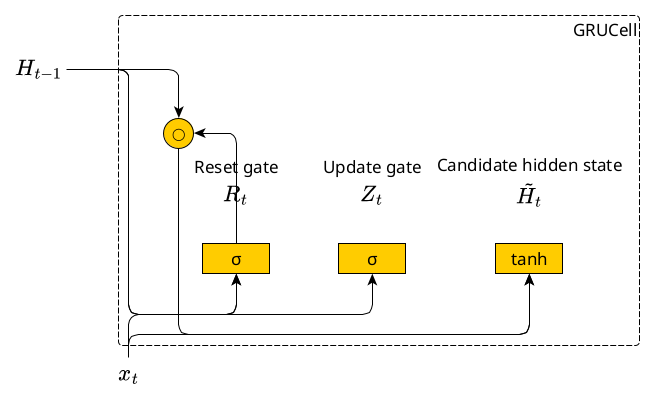

#### Hidden State

Наконец, необходимо учесть влияние `update gate` (вентиля обновления) $Z_t$. Он определяет, в какой степени новое скрытое состояние совпадает с предыдущим состоянием и в какой степени оно приближается к новому кандидатному состоянию $\tilde{H}_t$. Для этого используется поэлементная выпуклая комбинация предыдущего скрытого состояния $H_{t-1}$ и обновлённого состояния $\tilde{H}_t$, взвешенная значениями `update gate` (вентиля обновления). В результате получаем итоговое уравнение обновления скрытого состояния в модели `GRU`:

\begin{equation}
H_t = Z_t \odot H_{t-1} + (1 - Z_t) \odot \tilde{H}_t.
\end{equation}

Если значения `update gate` (вентиля обновления) близки к $1$, новое скрытое состояние практически совпадает с предыдущим состоянием $H_{t-1}$. В этом случае информация из обновлённого состояния $\tilde{H}_t$ игнорируется, что эквивалентно пропуску временного шага в цепочке зависимостей. Напротив, когда значения `update gate` (вентиля обновления) близки к $0$, новое скрытое состояние $H_t$ приближается к обновлённому скрытому состоянию $\tilde{H}_t$. Таким образом, модель активно обновляет своё внутреннее представление на данном временном шаге.

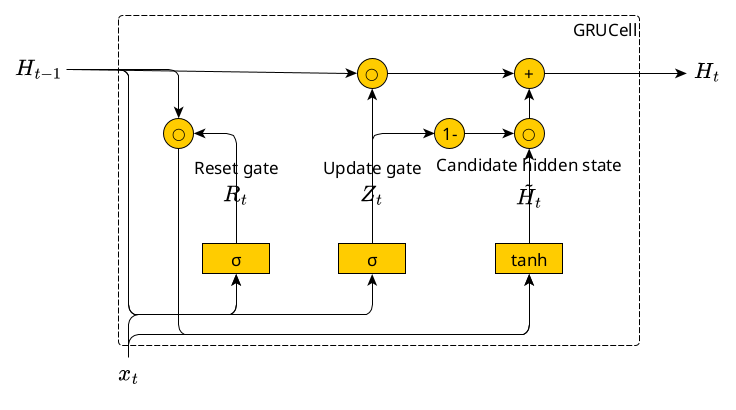

Модель GRU обладает двумя ключевыми отличительными особенностями:

- `reset gates` (вентили сброса) способствуют захвату краткосрочных зависимостей в последовательностях;
- `update gates` вентили обновления позволяют эффективно моделировать долгосрочные зависимости.

#### Полная система уравнений `GRU`

\begin{align}
z_t &= \sigma\left(W_z [x_t, h_{t-1}] + b_z\right), \\
r_t &= \sigma\left(W_r [x_t, h_{t-1}] + b_r\right), \\
\tilde{h}_t &= \tanh\left(W_h [x_t, r_t \odot h_{t-1}] + b_h\right), \\
h_t &= (1 - z_t) \odot h_{t-1} + z_t \odot \tilde{h}_t.
\end{align}

In [ ]:
# ============================================================
# 3) GRU
# ============================================================
class GRUCell(nn.Module):
    def __init__(self, input_size: int, hidden_size: int):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size

        # We'll compute z and r in one affine; and candidate in another.
        self.x_zr = nn.Linear(input_size, 2 * hidden_size, bias=True)
        self.h_zr = nn.Linear(hidden_size, 2 * hidden_size, bias=False)

        self.x_h = nn.Linear(input_size, hidden_size, bias=True)
        self.h_h = nn.Linear(hidden_size, hidden_size, bias=False)

    def forward(self, x_t: torch.Tensor, h_prev: torch.Tensor) -> torch.Tensor:
        zr = self.x_zr(x_t) + self.h_zr(h_prev)  # (B,2H)
        z, r = zr.chunk(2, dim=-1)
        z = torch.sigmoid(z)
        r = torch.sigmoid(r)

        h_tilde = torch.tanh(self.x_h(x_t) + self.h_h(r * h_prev))
        h_t = (1.0 - z) * h_prev + z * h_tilde
        return h_t


class GRU(nn.Module):
    def __init__(self, input_size: int, hidden_size: int):
        super().__init__()
        self.cell = GRUCell(input_size, hidden_size)

    def forward(self, x: torch.Tensor, h0: torch.Tensor | None = None) -> SeqOut:
        B, T, _ = x.shape
        device, dtype = x.device, x.dtype

        h_t = h0 if h0 is not None else _init_state(B, self.cell.hidden_size, device, dtype)

        ys = []
        for t in range(T):
            h_t = self.cell(x[:, t, :], h_t)
            ys.append(h_t.unsqueeze(1))

        y = torch.cat(ys, dim=1)
        return SeqOut(y=y, h_T=h_t, c_T=None)

In [ ]:
gru_model = GRU(D, H)
y_gru = gru_model(x)
print("GRU:  ", y_gru.y.shape, y_gru.h_T.shape, y_gru.c_T)

GRU:   torch.Size([4, 7, 16]) torch.Size([4, 16]) None


#### Общий вывод

По сравнению с `LSTM`, модели `GRU` достигают сопоставимого качества, но, как правило, обладают меньшей вычислительной сложностью. В целом, по сравнению с простыми рекуррентными нейронными сетями, модели с вентилями, такие как `LSTM` и `GRU`, значительно лучше справляются с моделированием зависимостей в последовательностях с большими временными интервалами.

Модели `GRU` включают в себя обычные `RNN` как предельный случай: когда вентиль сброса полностью открыт, `GRU` эквивалентна базовой рекуррентной сети. Кроме того, за счёт вентиля обновления GRU может эффективно пропускать подпоследовательности, уменьшая влияние отдельных временных шагов на дальнейшую динамику скрытого состояния.

### `xLSTM` — extended LSTM

`xLSTM` — это обобщение классической архитектуры `LSTM`, разработанное для устранения ключевых ограничений рекуррентных нейронных сетей при работе с длинными и сложными последовательностями. В основе `xLSTM` лежит идея структурированной памяти, которая позволяет модели не только накапливать информацию во времени, но и адаптивно пересматривать и перераспределять её по мере поступления новых данных.

В отличие от классического `LSTM`, где память представлена скалярным состоянием ячейки, xLSTM использует многомерные и матричные представления памяти, что существенно повышает ёмкость модели и её выразительную способность. Архитектура включает специализированные варианты ячеек (`sLSTM` и `mLSTM`), которые обеспечивают:

- более устойчивое хранение редкой и долгосрочной информации,

- гибкое обновление памяти,

- лучшее масштабирование по длине последовательности по сравнению с традиционными `RNN`.

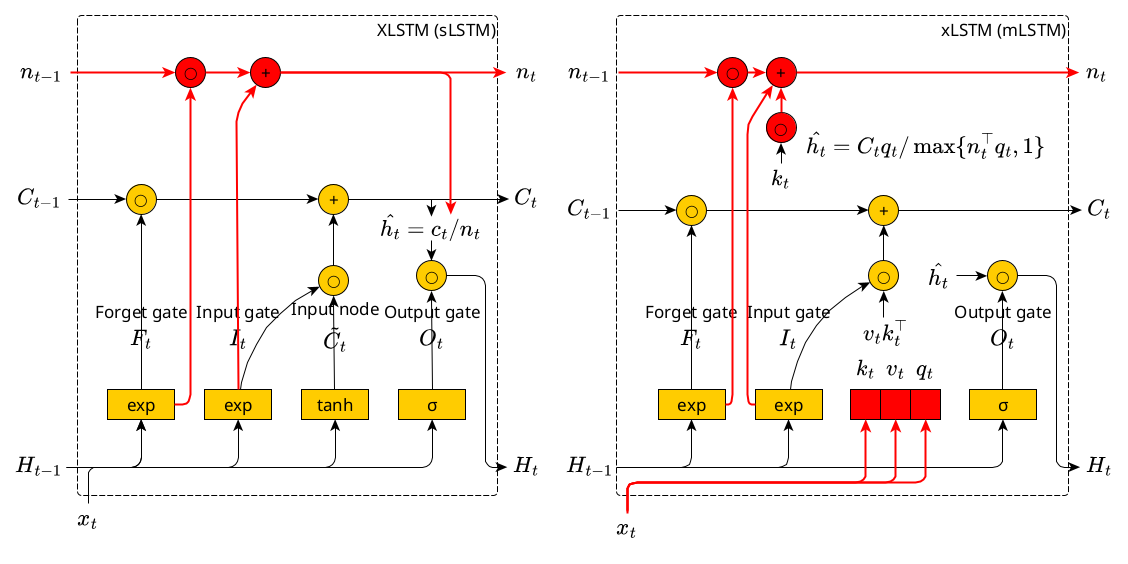

##### sLSTM (Scalar LSTM)

Пусть $x_t \in \mathbb{R}^d$, $h_t \in \mathbb{R}^h$, $c_t \in \mathbb{R}^h$.

\begin{equation}
\begin{aligned}
f_t &= \sigma(W_f x_t + U_f h_{t-1} + b_f), \\
i_t &= \sigma(W_i x_t + U_i h_{t-1} + b_i), \\
o_t &= \sigma(W_o x_t + U_o h_{t-1} + b_o),
\end{aligned}
\end{equation}
\begin{equation}
\tilde{c}_t = \tanh(W_c x_t + U_c h_{t-1} + b_c).
\end{equation}
Нормализованное экспоненциальное обновление памяти:
\begin{equation}
c_t =
\frac{f_t \odot c_{t-1} + i_t \odot \tilde{c}_t}
{\left\| f_t \odot c_{t-1} + i_t \odot \tilde{c}_t \right\|_1 + \varepsilon}.
\end{equation}
Скрытое состояние:
\begin{equation}
h_t = o_t \odot \tanh(c_t).
\end{equation}

##### mLSTM (Matrix LSTM)

Пусть матричная память $C_t \in \mathbb{R}^{h \times h}$.

\begin{equation}
\begin{aligned}
f_t &= \sigma(W_f x_t + U_f h_{t-1}), \\
i_t &= \sigma(W_i x_t + U_i h_{t-1}), \\
o_t &= \sigma(W_o x_t + U_o h_{t-1}),
\end{aligned}
\end{equation}
ключи, значения и запрос:
\begin{equation}
k_t = W_k x_t, \qquad
v_t = W_v x_t, \qquad
q_t = W_q x_t.
\end{equation}
Обновление матричной памяти:
\begin{equation}
C_t = f_t \odot C_{t-1} + i_t \odot (k_t v_t^{\top}).
\end{equation}
Чтение из памяти:
\begin{equation}
h_t = o_t \odot (C_t q_t).
\end{equation}

##### Композиция xLSTM



Чередование блоков sLSTM и mLSTM по слоям:
\begin{equation}
h_t^{(l+1)} =
\begin{cases}
\mathrm{sLSTM}\!\left(h_t^{(l)}, h_{t-1}^{(l+1)}\right), & l \in \mathcal{S},\\
\mathrm{mLSTM}\!\left(h_t^{(l)}, h_{t-1}^{(l+1)}\right), & l \in \mathcal{M}.
\end{cases}
\end{equation}

### Общий выводы

Рекуррентные нейронные сети представляют собой фундаментальный класс моделей для работы с последовательными данными, в которых ключевую роль играет понятие *внутреннего состояния*, эволюционирующего во времени. В отличие от моделей, обрабатывающих данные фиксированной длины, рекуррентные архитектуры позволяют явно учитывать временной порядок и накапливать информацию о прошлом, что делает их естественным инструментом для анализа временных рядов, текста, аудиосигналов и других последовательностей.

Базовые RNN формируют минимальную модель такой динамики, однако их практическое применение ограничено проблемами исчезающих и взрывающихся градиентов. Эти ограничения носят не эвристический, а структурный характер и напрямую связаны со спектральными свойствами рекуррентного перехода. В ответ на эти фундаментальные трудности были разработаны модели с управляемой памятью, такие как `LSTM` и `GRU`, в которых механизм вентилей обеспечивает стабильное распространение информации и градиентов на больших временных горизонтах.

Развитие рекуррентных моделей демонстрирует постепенный переход от простых скалярных состояний к более сложным и выразительным формам памяти, включая матричные и ассоциативные представления. Современные архитектуры, такие как xLSTM, показывают, что идеи рекуррентности, управляемой памяти и селективного обновления остаются актуальными и могут конкурировать с нерекуррентными подходами, особенно в задачах, где важны причинность, потоковая обработка и компактность вычислений.

В целом рекуррентные модели следует рассматривать не как устаревший класс архитектур, а как важный концептуальный слой в эволюции моделей последовательностей. Они заложили основы понимания долгосрочной памяти, управления информационными потоками и динамики обучения во времени — идей, которые продолжают развиваться и переосмысливаться в современных моделях последовательной обработки данных.

Frame 2087329782.png